# Introduction to Numerical Derivatives and Integrals

In this tutorial, we will use Python to investigate how derivatives and integrals can be approximated numerically.

## Learning objectives

By the end of the tutorial, you should be able to:

1. approximate a derivative using a centered finite difference;
2. explain how the step size $h$ affects numerical error;
3. approximate a definite integral using Riemann sums;
4. explain how the number of rectangles affects accuracy; and
5. prompt an AI coding assistant and critically evaluate its output.

## Setup

NumPy provides numerical array operations, Matplotlib creates plots, and ipywidgets supplies interactive controls in Google Colab.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

# Part 1: Numerical differentiation

The derivative of a function is defined by

$$
f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h}.
$$

On a computer, we cannot set $h$ equal to zero. Instead, we choose a small nonzero value of $h$.

## 1. Define and plot a function

We will study

$$
f(x)=10+\left(\frac{x}{10}\right)^3e^{(x/10)^2}.
$$

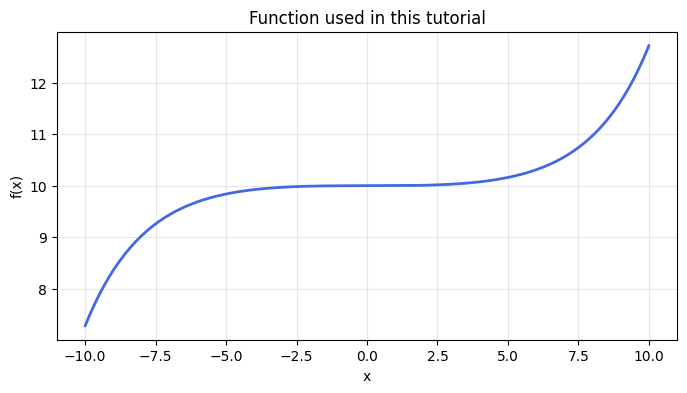

In [2]:
def f(x):
    u = x / 10
    return 10 + u**3 * np.exp(u**2)

x = np.linspace(-10, 10, 200)

plt.figure(figsize=(8, 4))
plt.plot(x, f(x), color='royalblue', linewidth=2)
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Function used in this tutorial')
plt.grid(alpha=0.3)
plt.show()

### Check your understanding

- What are the values of `f(-10)`, `f(0)`, and `f(10)`?
- Where does the function appear to change most rapidly?
- What is the difference between `plt.plot` and `plt.scatter`?

## 2. Centered finite differences

A common numerical approximation is the centered finite-difference formula

$$
f'(x)\approx\frac{f(x+h)-f(x-h)}{2h}.
$$

Before running the next cell, predict what might happen when $h$ is very large and when it is very small.

In [3]:
def df_dx(x, h):
    return (f(x + h) - f(x - h)) / (2 * h)

## 3. Analytical derivative

For comparison, the analytical derivative is

$$
f'(x)=\left[\frac{3}{10}\left(\frac{x}{10}\right)^2+\frac{1}{5}\left(\frac{x}{10}\right)^4\right]e^{(x/10)^2}.
$$

Equivalently,

$$
f'(x)=\left(\frac{3x^2}{1000}+\frac{x^4}{50000}\right)e^{(x/10)^2}.
$$

In [4]:
def df_dx_true(x):
    u = x / 10
    return ((3 / 10) * u**2 + (1 / 5) * u**4) * np.exp(u**2)

## 4. Compare the numerical and analytical derivatives

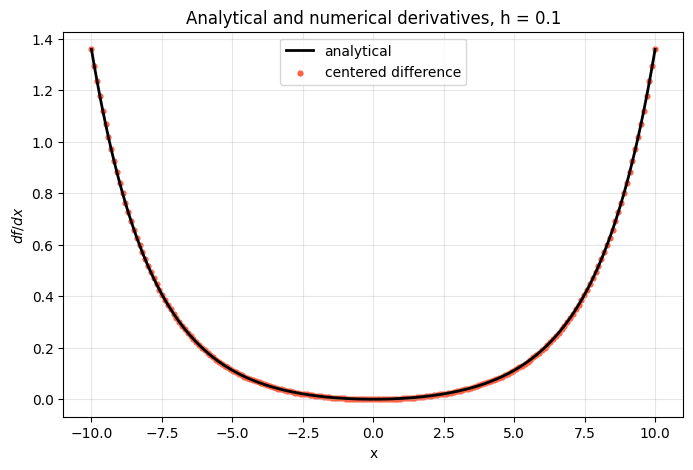

In [5]:
h = 0.1
df_numerical = df_dx(x, h)
df_exact = df_dx_true(x)

plt.figure(figsize=(8, 5))
plt.plot(x, df_exact, color='black', linewidth=2, label='analytical')
plt.scatter(x, df_numerical, color='tomato', s=12, label='centered difference')
plt.xlabel('x')
plt.ylabel(r'$df/dx$')
plt.title(f'Analytical and numerical derivatives, h = {h}')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 5. Vibe-coding exercise: make $h$ interactive

Ask a coding assistant to add an interactive control. Start with a short prompt, test its result, and refine the prompt when something is missing.

**Suggested prompt**

> Using the existing `x`, `f`, `df_dx`, and `df_dx_true` definitions, create an interactive Matplotlib plot controlled by an `ipywidgets.FloatLogSlider`. Let me drag $h$ from $10^{-2}$ to $5$. Keep the analytical derivative and plot axes fixed, update the numerical derivative while I drag the slider, and display the current $h$ in the title. Make it work in Google Colab without modifying earlier cells.

After generating the code, check that it reuses the existing functions, covers the requested range, fixes the axes, and produces scientifically sensible results. A working reference implementation is provided below.

In [6]:
h_reference = np.geomspace(1e-2, 5, 60)
reference_curves = [df_dx(x, value) for value in h_reference]
all_derivatives = np.concatenate([df_exact, *reference_curves])
y_min, y_max = all_derivatives.min(), all_derivatives.max()
y_margin = 0.05 * (y_max - y_min)

h_slider = widgets.FloatLogSlider(
    value=0.1, base=10, min=-2, max=np.log10(5), step=0.02,
    description='h:', continuous_update=True, readout_format='.3g',
    layout=widgets.Layout(width='700px')
)
plot_output = widgets.Output()

def update_derivative_plot(change=None):
    current_h = h_slider.value
    numerical = df_dx(x, current_h)
    error = numerical - df_exact

    with plot_output:
        clear_output(wait=True)
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
        ax1.plot(x, df_exact, color='black', linewidth=2, label='analytical')
        ax1.plot(x, numerical, color='tomato', linewidth=2, label='centered difference')
        ax1.set_ylim(y_min - y_margin, y_max + y_margin)
        ax1.set_ylabel(r'$df/dx$')
        ax1.set_title(f'Numerical derivative with h = {current_h:.3g}')
        ax1.grid(alpha=0.3)
        ax1.legend()

        ax2.plot(x, error, color='purple')
        ax2.axhline(0, color='black', linewidth=1)
        ax2.set_xlim(x.min(), x.max())
        ax2.set_ylim(-0.75, 0.75)
        ax2.set_xlabel('x')
        ax2.set_ylabel('error')
        ax2.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
        plt.close(fig)

h_slider.observe(update_derivative_plot, names='value')
display(h_slider, plot_output)
update_derivative_plot()

FloatLogSlider(value=0.1, description='h:', layout=Layout(width='700px'), max=0.6989700043360189, min=-2.0, st…

Output()

### Reflection

- How does the numerical derivative change as $h$ decreases?
- Is the error uniform across the interval?
- Why should you not assume that the smallest representable $h$ is always best?
- What did the coding assistant produce that you did not explicitly request?

## 6. Quantify the error

The root mean square error is

$$
\operatorname{RMSE}=\sqrt{\frac{1}{N}\sum_{i=1}^{N}(y_i-\hat y_i)^2},
$$

where $y_i$ is the numerical value and $\hat y_i$ is the analytical value.

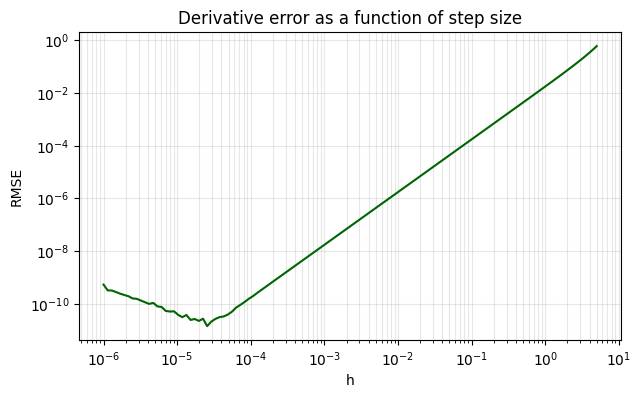

In [14]:
def rmse(numerical, exact):
    return np.sqrt(np.mean((numerical - exact)**2))

h_values = np.logspace(-6, 0.7, 120)
rmse_values = np.array([rmse(df_dx(x, value), df_exact) for value in h_values])

plt.figure(figsize=(7, 4))
plt.loglog(h_values, rmse_values, color='darkgreen')
plt.xlabel('h')
plt.ylabel('RMSE')
plt.title('Derivative error as a function of step size')
plt.grid(True, which='both', alpha=0.3)
plt.show()



The centered-difference truncation error generally decreases as $h$ decreases. For extremely small $h$, however, subtracting nearly equal floating-point numbers can amplify round-off error.

# Part 2: Numerical integration

A definite integral can be interpreted as the limit of a sum of rectangle areas:

$$
\int_a^b f(x)\,dx=\lim_{n\to\infty}\sum_{i=1}^{n}f(x_i^*)\,\Delta x,
\qquad \Delta x=\frac{b-a}{n}.
$$

We will integrate the same function over $[-11,11]$. Because $10$ is even and the second term is odd,

$$
\int_{-11}^{11}f(x)\,dx=10(22)=220.
$$

## 7. Visualize the area

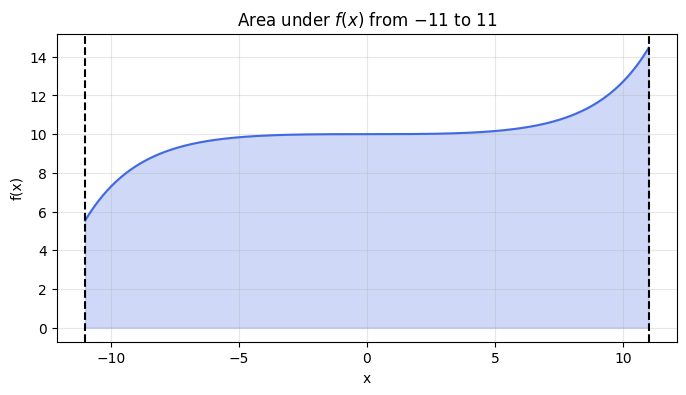

In [8]:
a, b = -11, 11
x_integral = np.linspace(a, b, 500)

plt.figure(figsize=(8, 4))
plt.plot(x_integral, f(x_integral), color='royalblue')
plt.fill_between(x_integral, f(x_integral), alpha=0.25, color='royalblue')
plt.axvline(a, color='black', linestyle='--')
plt.axvline(b, color='black', linestyle='--')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title(r'Area under $f(x)$ from $-11$ to $11$')
plt.grid(alpha=0.3)
plt.show()

## 8. Left, right, and midpoint Riemann sums

The three methods use the same rectangle width but evaluate the height at different locations in each subinterval.

In [9]:
def riemann_sum(f, a, b, n_rectangles, method='midpoint'):
    edges = np.linspace(a, b, n_rectangles + 1)
    width = (b - a) / n_rectangles

    if method == 'left':
        sample_points = edges[:-1]
    elif method == 'right':
        sample_points = edges[1:]
    elif method == 'midpoint':
        sample_points = (edges[:-1] + edges[1:]) / 2
    else:
        raise ValueError("method must be 'left', 'right', or 'midpoint'")

    return width * np.sum(f(sample_points))

for method in ['left', 'right', 'midpoint']:
    estimate = riemann_sum(f, a, b, n_rectangles=10, method=method)
    print(f'{method:>8}: {estimate:.6f}')

    left: 210.180326
   right: 229.819674
midpoint: 220.000000


### Check your understanding

- Which method is most accurate with 10 rectangles?
- Why are the left and right estimates different?
- What symmetry in the function helps explain the exact integral?

## 9. Visualize a midpoint sum

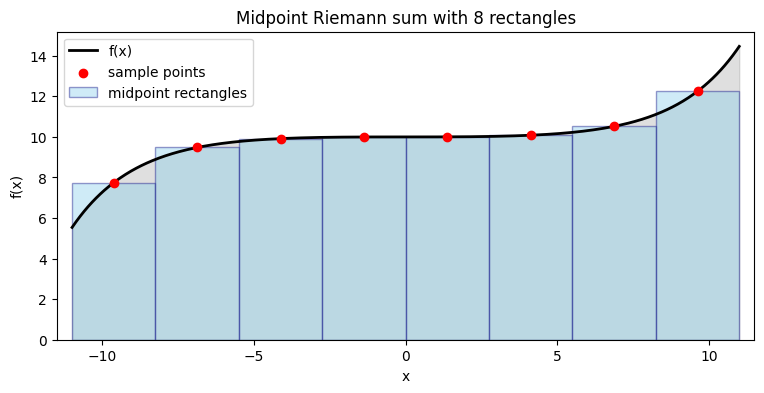

Numerical integral: 220.000000
Exact integral:     220.000000


In [18]:
n_rectangles = 8
edges = np.linspace(a, b, n_rectangles + 1)
width = (b - a) / n_rectangles
midpoints = (edges[:-1] + edges[1:]) / 2
heights = f(midpoints)

plt.figure(figsize=(9, 4))
plt.plot(x_integral, f(x_integral), color='black', linewidth=2, label='f(x)')
plt.fill_between(x_integral, f(x_integral), alpha=0.25, color='gray')
plt.bar(midpoints, heights, width=width, alpha=0.4, color='skyblue',
        edgecolor='navy', align='center', label='midpoint rectangles')
plt.scatter(midpoints, heights, color='red', zorder=3, label='sample points')
plt.xlim(a-0.5, b+0.5)
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title(f'Midpoint Riemann sum with {n_rectangles} rectangles')
plt.legend()
plt.show()

print(f'Numerical integral: {width * np.sum(heights):.6f}')
print('Exact integral:     220.000000')

## 10. Integration convergence

Investigate how the error changes as the number of rectangles increases. For this experiment, we use the non-symmetric interval $[0,11]$ so that symmetry does not make some of the sums exact automatically.

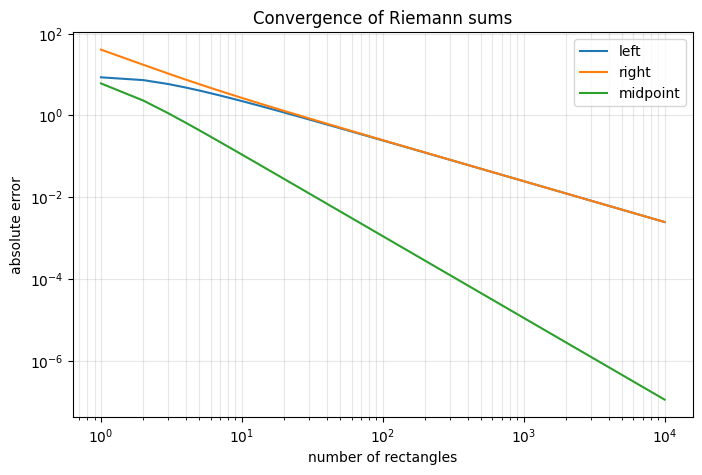

In [11]:
convergence_a, convergence_b = 0, 11
exact_integral = 115 + 1.05 * np.exp(1.21)
rectangle_counts = np.unique(np.logspace(0, 4, 80).astype(int))
methods = ['left', 'right', 'midpoint']

plt.figure(figsize=(8, 5))
for method in methods:
    errors = [
        abs(riemann_sum(f, convergence_a, convergence_b, n, method) - exact_integral)
        for n in rectangle_counts
    ]
    plt.loglog(rectangle_counts, errors, label=method)

plt.xlabel('number of rectangles')
plt.ylabel('absolute error')
plt.title('Convergence of Riemann sums')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.show()

## 11. Challenge function

Apply the midpoint method to

$$
g(x)=\cos^2(5x)+x^2,\qquad -1\le x\le1.
$$

Its exact integral is

$$
\int_{-1}^{1}g(x)\,dx=1+\frac{\sin(10)}{10}+\frac{2}{3}\approx1.6123.
$$

In [12]:
def g(x):
    return np.cos(5 * x)**2 + x**2

g_exact = 1 + np.sin(10) / 10 + 2 / 3

for n_rectangles in [2, 5, 10, 50, 100]:
    estimate = riemann_sum(g, -1, 1, n_rectangles, method='midpoint')
    print(
        f'n = {n_rectangles:3d}: estimate = {estimate:.8f}, '
        f'error = {abs(estimate - g_exact):.3e}'
    )

n =   2: estimate = 1.78366219, error = 1.714e-01
n =   5: estimate = 1.52034254, error = 9.192e-02
n =  10: estimate = 1.59534880, error = 1.692e-02
n =  50: estimate = 1.61163351, error = 6.310e-04
n = 100: estimate = 1.61210711, error = 1.574e-04


# Final reflection

1. What role does $h$ play in numerical differentiation?
2. What role does $\Delta x$ play in numerical integration?
3. Why can increasing numerical resolution improve an approximation?
4. Why does higher resolution also increase computational cost?
5. What checks should you perform before trusting AI-generated scientific code?
6. Describe one prompt refinement that improved the code produced during this tutorial.